# 02 · The perfect detector: right answer, wrong remedy

**Block 2 · W44, notebook 2 of 2.** Notebook 1 showed that a *perfect* drift detector, which fires at every true
level break and only then, loses to a dumb weekly cron (MASE 1.3685 against 0.9829). The plan explains it by the
slow seasonal drift that a break detector cannot see, and concludes that "drift detection answers the wrong
question". This notebook tests that explanation, finds another one, and measures what a detector is worth when
its answer is actually used.

| § | Question | Short answer |
|---|---|---|
| 1 | Does the refit happen at a useful time? | No: with d = 48 a refit at the break cannot see it. |
| 2 | Is the seasonal drift the cause? | No: switch it off and the detector still loses by 34%. |
| 3 | What does one refit do to a break? | Almost nothing: a 240-hour mean absorbs a break slowly. |
| 4 | What if the remedy uses the detection? | Window reset + weekly cron beats continuous retraining, 5 seeds out of 5. |
| 5 | Does it hold over seeds? | Paired per seed, yes for the combination; a tie for the reset alone. |
| 6 | And with a real detector? | A CUSUM-driven reset is worse; the CUSUM's own targeting was half a leak. |

> **How to read this notebook.** Callouts follow a fixed code:
> **Intuition**, the idea without equations · **Example**, a measured experiment ·
> **Watch out**, the trap to avoid · **Takeaway**, the note to keep.

In [1]:
import logging, warnings; warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from w44_retraining import viz
from w44_retraining.park import make_park
from w44_retraining.harness import Bench, BreakReset, Calendar, KnownBreaks, run
from w44_retraining.harness_study import study

viz.setup()
export = viz.exporter("../figures")
bench = Bench()
park = make_park()
SERIES, BREAK = 43, 1078
out = study()          # every experiment of this notebook, about 25 s (also `uv run w44 harness`)


def table(d: dict, cols=("mase", "jump_p95", "pct_visible", "n_refit")) -> None:
    head = {"mase": "MASE", "churn": "churn", "jump_p95": "jump p95", "pct_visible": "% visible", "n_refit": "refits / series",
            "useful": "useful"}
    fmt = {"mase": "{:.4f}", "churn": "{:.4f}", "jump_p95": "{:.4f}", "pct_visible": "{:.1%}", "n_refit": "{:.1f}", "useful": "{:.1%}"}
    rows = ["| policy | " + " | ".join(head[c] for c in cols) + " |", "|---" * (len(cols) + 1) + "|"]
    rows += [f"| {k} | " + " | ".join(fmt[c].format(r[c]) for c in cols) + " |" for k, r in d.items()]
    display(Markdown("\n".join(rows)))

## 1. When does the perfect detector refit, and with which data?

**Question.** The detector fires exactly at the break. What does the refit see?

> **Intuition.** Notebook 1, section 2: a refit at hour t uses the window closed at t - 48. A refit *at* the
> break is fit on data that ends 48 hours *before* the break. The detector is right about **when** something
> happened, and the remedy is applied with data that cannot contain it.

**Experiment.** Same perfect detector, but the refit is delayed by `delay` hours after each break.

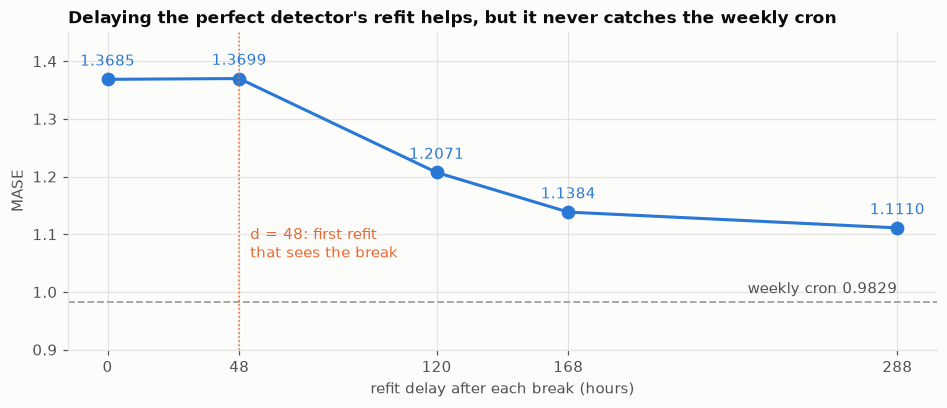

In [2]:
delays = list(out["oracle_delay"])
mase = [out["oracle_delay"][d_]["mase"] for d_ in delays]
weekly = out["plan"]["calendar k=168 (weekly)"]["mase"]
fig, ax = plt.subplots(figsize=(8.5, 3.6), layout="constrained")
ax.plot(delays, mase, color=viz.BLUE, marker="o", ms=8)
for d_, m_ in zip(delays, mase):
    ax.annotate(f"{m_:.4f}", (d_, m_), textcoords="offset points", xytext=(0, 9), ha="center", color=viz.BLUE)
ax.axhline(weekly, color=viz.MUTED, ls="--", lw=1.2)
ax.text(delays[-1], weekly + 0.015, f"weekly cron {weekly:.4f}", color=viz.TEXT_2, ha="right")
ax.axvline(bench.d, color=viz.ORANGE, ls=":", lw=1)
ax.text(bench.d + 4, 1.06, "d = 48: first refit\nthat sees the break", color=viz.ORANGE)
ax.set_xticks(delays)
ax.set_xlabel("refit delay after each break (hours)"); ax.set_ylabel("MASE")
ax.set_ylim(0.9, 1.45)
ax.set_title("Delaying the perfect detector's refit helps, but it never catches the weekly cron")
export(fig, "oracle_refit_delay"); plt.show()

Reading: firing at the break (delay 0) or at the first moment the break is closed (delay 48) gives the same
MASE, 1.3685 and 1.3699: in both cases the window holds at most one post-break hour. Waiting until the whole
window is post-break (delay 288 = 48 + 240) brings it to 1.1110, still far from the weekly cron at 0.9829.

> **Watch out.** The plan's "useful refit" KPI counts a refit as useful when a break happened in the previous
> 72 hours. With d = 48, most of those refits cannot see the break. The KPI rewards exactly the refits that are
> useless.

## 2. Is the slow seasonal drift the cause?

**Question.** The plan says the detector loses because it is blind to the drifting daily amplitude. If so,
switching that drift off should let it win.

**Experiment.** Same park, same breaks (same seed and draws), `seas_drift = 0`: the only drift left is the one the
detector sees perfectly.

In [3]:
table(out["no_seasonal_drift"])

| policy | MASE | jump p95 | % visible | refits / series |
|---|---|---|---|---|
| never | 1.4694 | 0.0000 | 0.0% | 0.0 |
| calendar k=168 (weekly) | 0.9425 | 1.2703 | 0.6% | 12.0 |
| calendar k=24 (daily) | 0.8811 | 0.2147 | 4.1% | 85.0 |
| known breaks (plan) | 1.2620 | 2.2760 | 0.2% | 3.7 |
| known breaks + window reset | 0.8477 | 1.9213 | 0.5% | 10.2 |

With level breaks only, the perfect detector (plan remedy) scores 1.2620 against 0.9425 for the weekly cron: it
still loses, by 34%. The plan's own stopping rule was "if the perfect detector wins, the DGP has only one kind of
drift". Here the DGP *has* only one kind of drift, and the detector does not win. So the seasonal drift is not
the main mechanism.

> **Takeaway.** When a story explains a result, switch off the ingredient the story relies on and re-run. If the
> result survives, the story was not the cause.

## 3. What one refit does to a break

**Question.** If timing and seasonal drift are not enough, what is?

> **Intuition.** The served level is the mean of the last 240 closed hours. After a break of size B, a window
> that holds j post-break hours moves the mean by about B x j / 240. One refit shortly after the break moves it
> by a few percent of B. A calendar refits again and again, so its window slides over the break and its level
> catches up within 240 hours. The perfect detector refits **once** per break and then waits for the next one.

**Example.** Series 43 around its break at hour 1,078 (+2.0 on the level): the served level under three
policies, against the daily mean of the data.

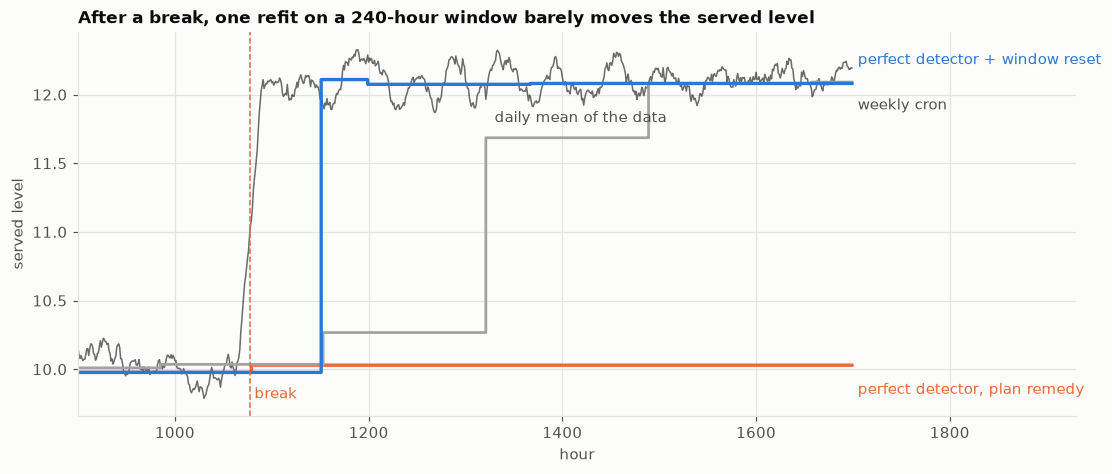

In [4]:
lo, hi = 900, 1700
y = park.y[SERIES]
day = np.convolve(y, np.ones(24) / 24, mode="same")
warm = bench.warm(park.spec.m)
hours = np.arange(warm, park.y.shape[1] - bench.h)
policies = [(KnownBreaks(), "perfect detector, plan remedy", viz.ORANGE),
            (Calendar(k=168), "weekly cron", viz.MUTED),
            (BreakReset(offsets=(24, 72, 240)), "perfect detector + window reset", viz.BLUE)]
fig, ax = plt.subplots(figsize=(10, 4.2), layout="constrained")
ax.plot(np.arange(lo, hi), day[lo:hi], color=viz.TEXT, lw=1, alpha=0.6)
ax.text(1330, 11.8, "daily mean of the data", color=viz.TEXT_2)
ends = {}
for pol, label, col in policies:
    tr: list = []
    run(park, pol, bench, trace=tr)
    lvl = np.array(tr)[:, SERIES]
    sel = (hours >= lo) & (hours < hi)
    ax.step(hours[sel], lvl[sel], where="post", color=col, lw=2.2 if col != viz.MUTED else 1.8)
    ends[label] = lvl[sel][-1]
offs = {"perfect detector, plan remedy": -0.18, "weekly cron": -0.17, "perfect detector + window reset": 0.17}
for (pol, label, col) in policies:
    ax.text(hi + 5, ends[label] + offs[label], label, color=col if col != viz.MUTED else viz.TEXT_2, va="center")
ax.axvline(BREAK, color=viz.ORANGE, ls="--", lw=1)
ax.text(BREAK + 4, day[lo:hi].min(), "break", color=viz.ORANGE)
ax.set_xlim(lo, hi + 230)
ax.set_xlabel("hour"); ax.set_ylabel("served level")
ax.set_title("After a break, one refit on a 240-hour window barely moves the served level")
export(fig, "break_zoom_served_level"); plt.show()

Reading: the plan's remedy refits at the break with data closed 48 hours earlier, so the served level stays on
the old value (orange) until the next break, 700 hours later. The weekly cron climbs in steps, each refit
sliding its window further past the break, and catches up after three refits, about 400 hours (grey). The window reset (blue) refits at break + 48 + {24, 72, 240} hours on a
window that **starts at the break**: 24 clean post-break hours are enough to jump straight to the new level.

## 4. A remedy that uses the detection

**Question.** What is a perfect detection worth when the refit uses it?

`BreakReset` keeps the perfect detector but changes the remedy: after a break at c, refit at c + 48 + 24,
c + 48 + 72 and c + 48 + 240, each time on a window that starts at the break (cut to whole days). Its weekly
variant also refits every 168 hours, with the same break-aware window, for the gradual drift that no detector
sees.

In [5]:
table(out["remedies"])

| policy | MASE | jump p95 | % visible | refits / series |
|---|---|---|---|---|
| calendar k=168 (weekly) | 0.9829 | 1.2647 | 0.6% | 12.0 |
| calendar k=1 (continuous) | 0.8915 | 0.0132 | 12.6% | 2063.0 |
| cusum on realised error | 0.9189 | 0.2797 | 4.2% | 92.5 |
| known breaks (plan) | 1.3685 | 2.2602 | 0.2% | 3.7 |
| known breaks + window reset | 0.9489 | 1.9356 | 0.5% | 10.2 |
| known breaks + window reset + weekly | 0.8789 | 1.4617 | 1.1% | 22.2 |
| cusum + window reset | 0.9189 | 0.2797 | 4.2% | 92.5 |

Reading: the same perfect detection goes from 1.3685 (plan remedy) to 0.9489 with a window reset, now slightly
better than weekly (0.9829) with fewer refits (10.2 against 12.0). Add the weekly cron for the seasonal drift and
it reaches 0.8789, **better than continuous retraining (0.8915) with 22.2 refits instead of 2,063**.

The last row, a CUSUM that restarts the window at its own change-time estimate, is identical to the plain CUSUM:
reading unclosed errors (the plan's setting), its estimate always falls after the newest closed hour, so the
reset never applies. Section 6 runs it with closed errors.

> **Takeaway.** Detection and remediation are two decisions. A detector tells you *when*; the remedy decides
> *what the model learns from it*. A fixed-window refit throws the detection away.

## 5. Does it hold beyond one seed?

**Question.** Are these gaps larger than what a different random park would give?

Five parks (seeds 44 to 48), every policy run on each. Because the parks differ a lot (the weekly cron alone
ranges over several hundredths of MASE), we compare policies **paired by seed**: for each seed, MASE of the
policy minus MASE of the reference on the same park.

weekly cron alone over the 5 seeds: MASE from 0.9436 to 0.9829 (range 0.0394)


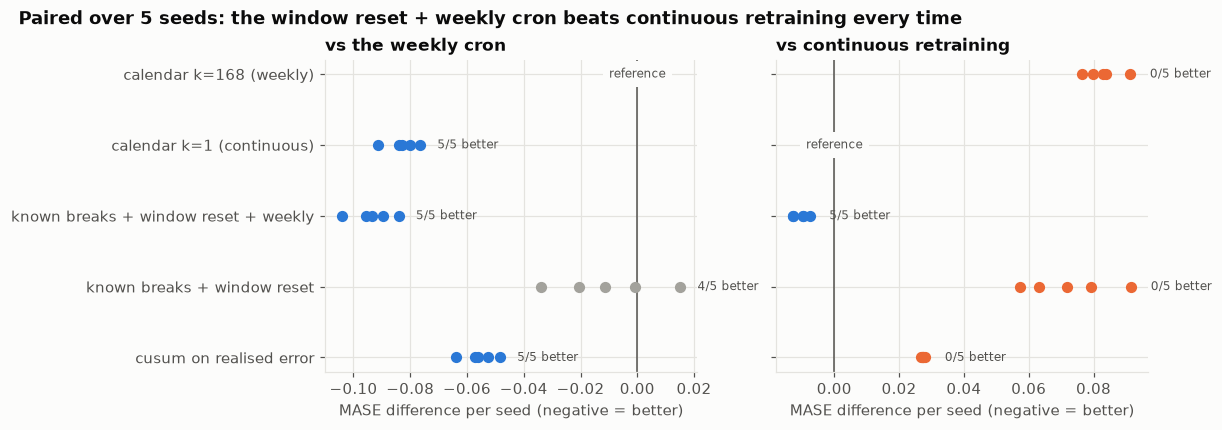

| policy | vs weekly: mean [min, max] | vs continuous: mean [min, max] |
|---|---|---|
| cusum on realised error | -0.0556 [-0.0640, -0.0483] | +0.0273 [+0.0267, +0.0281] |
| known breaks + window reset | -0.0103 [-0.0340, +0.0152] | +0.0726 [+0.0574, +0.0917] |
| known breaks + window reset + weekly | -0.0934 [-0.1040, -0.0840] | -0.0105 [-0.0128, -0.0076] |
| calendar k=1 (continuous) | -0.0829 [-0.0914, -0.0764] | reference |
| calendar k=168 (weekly) | reference | +0.0829 [+0.0764, +0.0914] |

In [6]:
seeds = out["seeds"]
w = seeds["calendar k=168 (weekly)"]
print(f"weekly cron alone over the 5 seeds: MASE from {w.min():.4f} to {w.max():.4f} (range {w.max() - w.min():.4f})")
refs = [("calendar k=168 (weekly)", "vs the weekly cron"), ("calendar k=1 (continuous)", "vs continuous retraining")]
order = ["cusum on realised error", "known breaks + window reset", "known breaks + window reset + weekly",
         "calendar k=1 (continuous)", "calendar k=168 (weekly)"]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained", sharey=True)
for ax, (ref, title) in zip(axs, refs):
    for i, n in enumerate(order):
        if n == ref:
            ax.text(0, i, "reference", va="center", ha="center", color=viz.TEXT_2, fontsize=8,
                    bbox=dict(facecolor=viz.SURFACE, edgecolor="none"))
            continue
        d_ = seeds[n] - seeds[ref]
        col = viz.BLUE if (d_ < 0).all() else (viz.ORANGE if (d_ > 0).all() else viz.MUTED)
        ax.scatter(d_, [i] * len(d_), color=col, s=40, zorder=3)
        ax.text(d_.max() + 0.006, i, f"{(d_ < 0).sum()}/{len(d_)} better", va="center", color=viz.TEXT_2, fontsize=8)
    ax.axvline(0, color=viz.TEXT_2, lw=1)
    ax.set_yticks(range(len(order)), order)
    ax.set_xlabel("MASE difference per seed (negative = better)")
    ax.set_title(title)
fig.suptitle("Paired over 5 seeds: the window reset + weekly cron beats continuous retraining every time",
             x=0.01, ha="left", fontweight="bold")
export(fig, "paired_seeds"); plt.show()
rows = ["| policy | vs weekly: mean [min, max] | vs continuous: mean [min, max] |", "|---|---|---|"]
for n in order:
    cells = []
    for ref, _ in refs:
        if n == ref:
            cells.append("reference")
        else:
            d_ = seeds[n] - seeds[ref]
            cells.append(f"{d_.mean():+.4f} [{d_.min():+.4f}, {d_.max():+.4f}]")
    rows.append(f"| {n} | " + " | ".join(cells) + " |")
display(Markdown("\n".join(rows)))

Reading (blue: better on every seed; orange: worse on every seed; grey: mixed):

- the window reset alone beats the weekly cron on 4 seeds out of 5, by -0.0103 on average with a range that
  crosses zero: call it a tie, at fewer refits;
- the window reset + weekly cron beats continuous retraining on 5 seeds out of 5 (mean -0.0105), and the weekly
  cron on 5 out of 5;
- the CUSUM beats the weekly cron on every seed and loses to continuous on every seed.

> **Watch out.** A single-seed MASE table invites reading gaps of 0.01 as results. Here the weekly cron alone
> moves by 0.039 from one park to another; only paired differences are worth reading.

## 6. And with a real detector?

The perfect detector knows the true break times. A real one has to infer them from the errors. Two checks.

**The trigger must also respect the closing lag.** The plan's CUSUM reads, at hour t, the error of the forecast
made for hour t, but that actual is only closed at t + 48. Giving the CUSUM only closed errors (`err_lag = 48`):

In [7]:
table({f"cusum, err_lag = {k}" if isinstance(k, int) else f"cusum + window reset, err_lag = 48": v
       for k, v in out["cusum_err_lag"].items()}, cols=("mase", "churn", "jump_p95", "n_refit", "useful"))

| policy | MASE | churn | jump p95 | refits / series | useful |
|---|---|---|---|---|---|
| cusum, err_lag = 0 | 0.9189 | 0.0031 | 0.2797 | 92.5 | 40.9% |
| cusum, err_lag = 48 | 0.9179 | 0.0031 | 0.2549 | 90.1 | 20.0% |
| cusum + window reset, err_lag = 48 | 1.0445 | 0.0223 | 1.1742 | 86.0 | 21.4% |

Reading: with closed errors the CUSUM's MASE is unchanged (0.9179 against 0.9189), but its share of refits near
a break falls from **40.9% to 20.0%**. The plan's "3.4 times better targeted than the calendar" (40.9% against
12.2%) is half a leak; the honest figure is 1.6 times.

**A CUSUM-driven window reset is worse.** The CUSUM's change-time estimate (the last time its statistic was at
zero) can serve as the start of the window. With closed errors this gives 1.0445, worse than the same CUSUM
without reset (0.9179), with seven times its churn (0.0223 against 0.0031): false alarms cut the window down to a
few noisy days.

> **Takeaway.**
> 1. A perfect drift detector does lose to a weekly cron, but because its remedy (one refit on a fixed window,
>    with data closed before the break) wastes the detection, not because detection asks the wrong question.
> 2. With a remedy that restarts the window at the break, plus a slow calendar for gradual drift, the same
>    detection beats continuous retraining with 1% of its refits.
> 3. That gain needs confident break times. A noisy detector driving a window reset does harm; with a CUSUM,
>    keep the full-window refit.
> 4. Everything a policy reads (fit data, trigger errors, KPIs) must carry the same closing lag as production.